# DATA 621 Homework 4: Auto Insurance Crash Risk & Claim Cost

## Project Objective
This project uses a training set of roughly 8,000 auto insurance customers to build:

- **Binary logistic regression models** that predict `TARGET_FLAG` (1 = the customer's car was in a crash, 0 = no crash), and
- **Multiple linear regression models** that predict `TARGET_AMT` (the cost of the crash; 0 when there was no crash).

We will then select the best model of each type and use it to score the evaluation data set (probabilities, 0.5-threshold classifications, and predicted cost). Only the supplied variables, or variables derived from them, may be used (`INDEX` is an identifier and is excluded).

**Notebook roadmap:** 1. Load Data / EDA, 2. Data Preparation, 3. Build Models, 4. Select Models & Predictions.

# 1. Load Data/EDA
## 1.1 Dataset Overview & Data Quality Assessment

We start by importing the core libraries and loading the training and evaluation files. Before modeling we verify the size, scope and integrity of the data: how many customers and variables we have, how each variable is stored, and which values are missing.

The raw file stores dollar amounts as text (e.g. `$67,349`) and many categorical levels carry a `z_` prefix (e.g. `z_High School`). We convert the dollar columns to numbers up front so they can be summarized; the categorical labels are left untouched until the data preparation step.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", None)

base_url = "https://raw.githubusercontent.com/alinsimon/data621-data-mining/main/homeworks/hw04/data/"
local_dir = "../data/"

def load_csv(name):
    # Use the GitHub copy when available; fall back to the local file (e.g. before the data is merged to main)
    try:
        return pd.read_csv(base_url + name)
    except Exception:
        return pd.read_csv(local_dir + name)

train_df = load_csv("insurance_training_data.csv")
eval_df = load_csv("insurance-evaluation-data.csv")

# Dollar columns are stored as text such as "$67,349"
money_cols = ["INCOME", "HOME_VAL", "BLUEBOOK", "OLDCLAIM"]
for df in (train_df, eval_df):
    for col in money_cols:
        df[col] = pd.to_numeric(df[col].str.replace(r"[$,]", "", regex=True), errors="coerce")

print(f"Training set:   {train_df.shape[0]:,} customers x {train_df.shape[1]} variables")
print(f"Evaluation set: {eval_df.shape[0]:,} customers x {eval_df.shape[1]} variables")
train_df.head()

Training set:   8,161 customers x 26 variables
Evaluation set: 2,141 customers x 26 variables


,INDEX,TARGET_FLAG,TARGET_AMT,KIDSDRIV,AGE,HOMEKIDS,YOJ,INCOME,PARENT1,HOME_VAL,MSTATUS,SEX,EDUCATION,JOB,TRAVTIME,CAR_USE,BLUEBOOK,TIF,CAR_TYPE,RED_CAR,OLDCLAIM,CLM_FREQ,REVOKED,MVR_PTS,CAR_AGE,URBANICITY
0,1,0,0.0,0,60.0,0,11.0,67349.0,No,0.0,z_No,M,PhD,Professional,14,Private,14230,11,Minivan,yes,4461,2,No,3,18.0,Highly Urban/ Urban
1,2,0,0.0,0,43.0,0,11.0,91449.0,No,257252.0,z_No,M,z_High School,z_Blue Collar,22,Commercial,14940,1,Minivan,yes,0,0,No,0,1.0,Highly Urban/ Urban
2,4,0,0.0,0,35.0,1,10.0,16039.0,No,124191.0,Yes,z_F,z_High School,Clerical,5,Private,4010,4,z_SUV,no,38690,2,No,3,10.0,Highly Urban/ Urban
3,5,0,0.0,0,51.0,0,14.0,NaN,No,306251.0,Yes,M,<High School,z_Blue Collar,32,Private,15440,7,Minivan,yes,0,0,No,0,6.0,Highly Urban/ Urban
4,6,0,0.0,0,50.0,0,NaN,114986.0,No,243925.0,Yes,z_F,PhD,Doctor,36,Private,18000,1,z_SUV,no,19217,2,Yes,3,17.0,Highly Urban/ Urban


In [4]:
# Variable types and missing values
cat_cols = train_df.select_dtypes(include="object").columns.tolist()
num_cols = [c for c in train_df.select_dtypes(include="number").columns if c not in ("INDEX", "TARGET_FLAG", "TARGET_AMT")]

print(f"{len(num_cols)} numeric predictors: {num_cols}\n")
print(f"{len(cat_cols)} categorical predictors: {cat_cols}\n")

missing = pd.DataFrame({
    "missing": train_df.isnull().sum(),
    "pct_missing": (train_df.isnull().mean() * 100).round(2),
    "eval_pct_missing": (eval_df.isnull().mean() * 100).round(2),
})
missing = missing[missing["missing"] > 0].sort_values("missing", ascending=False)
display(missing)

13 numeric predictors: ['KIDSDRIV', 'AGE', 'HOMEKIDS', 'YOJ', 'INCOME', 'HOME_VAL', 'TRAVTIME', 'BLUEBOOK', 'TIF', 'OLDCLAIM', 'CLM_FREQ', 'MVR_PTS', 'CAR_AGE']

10 categorical predictors: ['PARENT1', 'MSTATUS', 'SEX', 'EDUCATION', 'JOB', 'CAR_USE', 'CAR_TYPE', 'RED_CAR', 'REVOKED', 'URBANICITY']



,missing,pct_missing,eval_pct_missing
JOB,526,6.45,6.49
CAR_AGE,510,6.25,6.03
HOME_VAL,464,5.69,5.18
YOJ,454,5.56,4.39
INCOME,445,5.45,5.84
AGE,6,0.07,0.05


## 1.2 The Target Variables & Baseline Statistics

There are two responses. `TARGET_FLAG` is binary, so we check how balanced it is. `TARGET_AMT` is zero for customers without a crash, so we look at its distribution among crashed customers only, which is what the cost model has to explain.

TARGET_FLAG: 73.6% no crash (0) | 26.4% crash (1)

Crash cost (TARGET_AMT > 0, n=2,153):
count      2153.00
mean       5702.18
std        7743.18
min          30.28
25%        2609.78
50%        4104.00
75%        5787.00
max      107586.14
Skewness: 5.64
TARGET_AMT > 0 only when TARGET_FLAG = 1: True


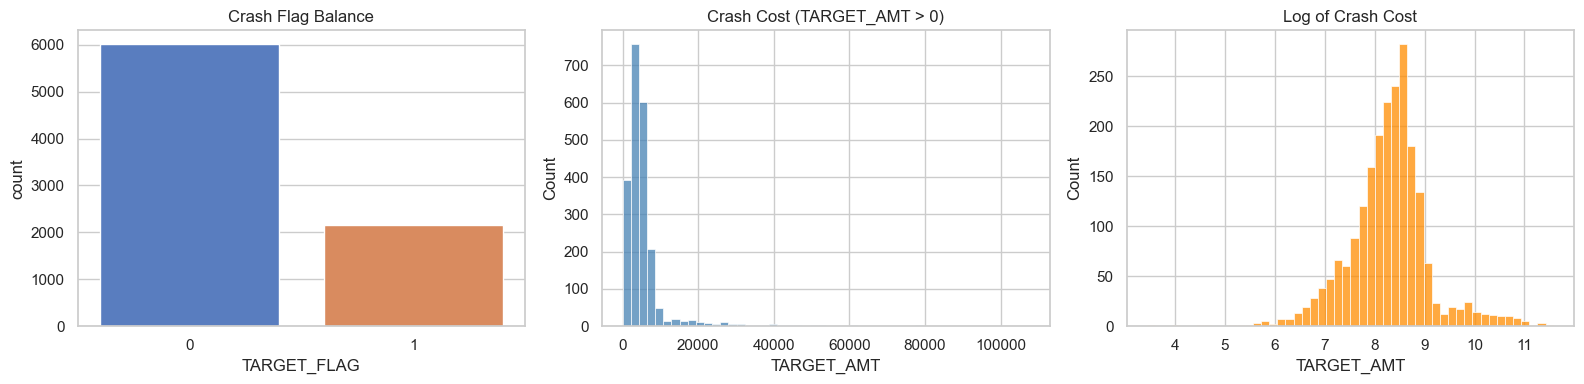

In [5]:
# TARGET_FLAG balance
flag_pct = train_df["TARGET_FLAG"].value_counts(normalize=True).mul(100)
print(f"TARGET_FLAG: {flag_pct[0]:.1f}% no crash (0) | {flag_pct[1]:.1f}% crash (1)")

# TARGET_AMT among crashes
crash_amt = train_df.loc[train_df["TARGET_FLAG"] == 1, "TARGET_AMT"]
print(f"\nCrash cost (TARGET_AMT > 0, n={len(crash_amt):,}):")
print(crash_amt.describe().round(2).to_string())
print(f"Skewness: {crash_amt.skew():.2f}")
print(f"TARGET_AMT > 0 only when TARGET_FLAG = 1: {((train_df['TARGET_AMT'] > 0) == (train_df['TARGET_FLAG'] == 1)).all()}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(x="TARGET_FLAG", data=train_df, hue="TARGET_FLAG", palette="muted", legend=False, ax=axes[0])
axes[0].set_title("Crash Flag Balance")
sns.histplot(crash_amt, bins=50, ax=axes[1], color="steelblue")
axes[1].set_title("Crash Cost (TARGET_AMT > 0)")
sns.histplot(np.log1p(crash_amt), bins=50, ax=axes[2], color="darkorange")
axes[2].set_title("Log of Crash Cost")
plt.tight_layout()
plt.show()

In [6]:
# Mean / standard deviation / median for numeric variables
summary = train_df[num_cols + ["TARGET_AMT"]].agg(["mean", "median", "std", "min", "max", "skew"]).round(2).T
display(summary)

,mean,median,std,min,max,skew
KIDSDRIV,0.17,0.0,0.51,0.0,4.00,3.35
AGE,44.79,45.0,8.63,16.0,81.00,-0.03
HOMEKIDS,0.72,0.0,1.12,0.0,5.00,1.34
YOJ,10.50,11.0,4.09,0.0,23.00,-1.20
INCOME,61898.09,54028.0,47572.68,0.0,367030.00,1.19
HOME_VAL,154867.29,161160.0,129123.77,0.0,885282.00,0.49
TRAVTIME,33.49,33.0,15.91,5.0,142.00,0.45
BLUEBOOK,15709.90,14440.0,8419.73,1500.0,69740.00,0.79
TIF,5.35,4.0,4.15,1.0,25.00,0.89
OLDCLAIM,4037.08,0.0,8777.14,0.0,57037.00,3.12


Only 26.4% of customers crashed, so the classes are imbalanced (about 3:1) but not extreme; we will judge the classifier on precision, sensitivity and AUC rather than accuracy alone. Crash costs are strongly right-skewed (median about $4,100, mean about $5,700, maximum about $107,600), so the cost model will likely benefit from a log transform or from being fit on crashed customers only.

## 1.3 Distributions of the Predictors

Box plots and bar charts show which variables are skewed, contain outliers, or have implausible values that will need attention in data preparation.

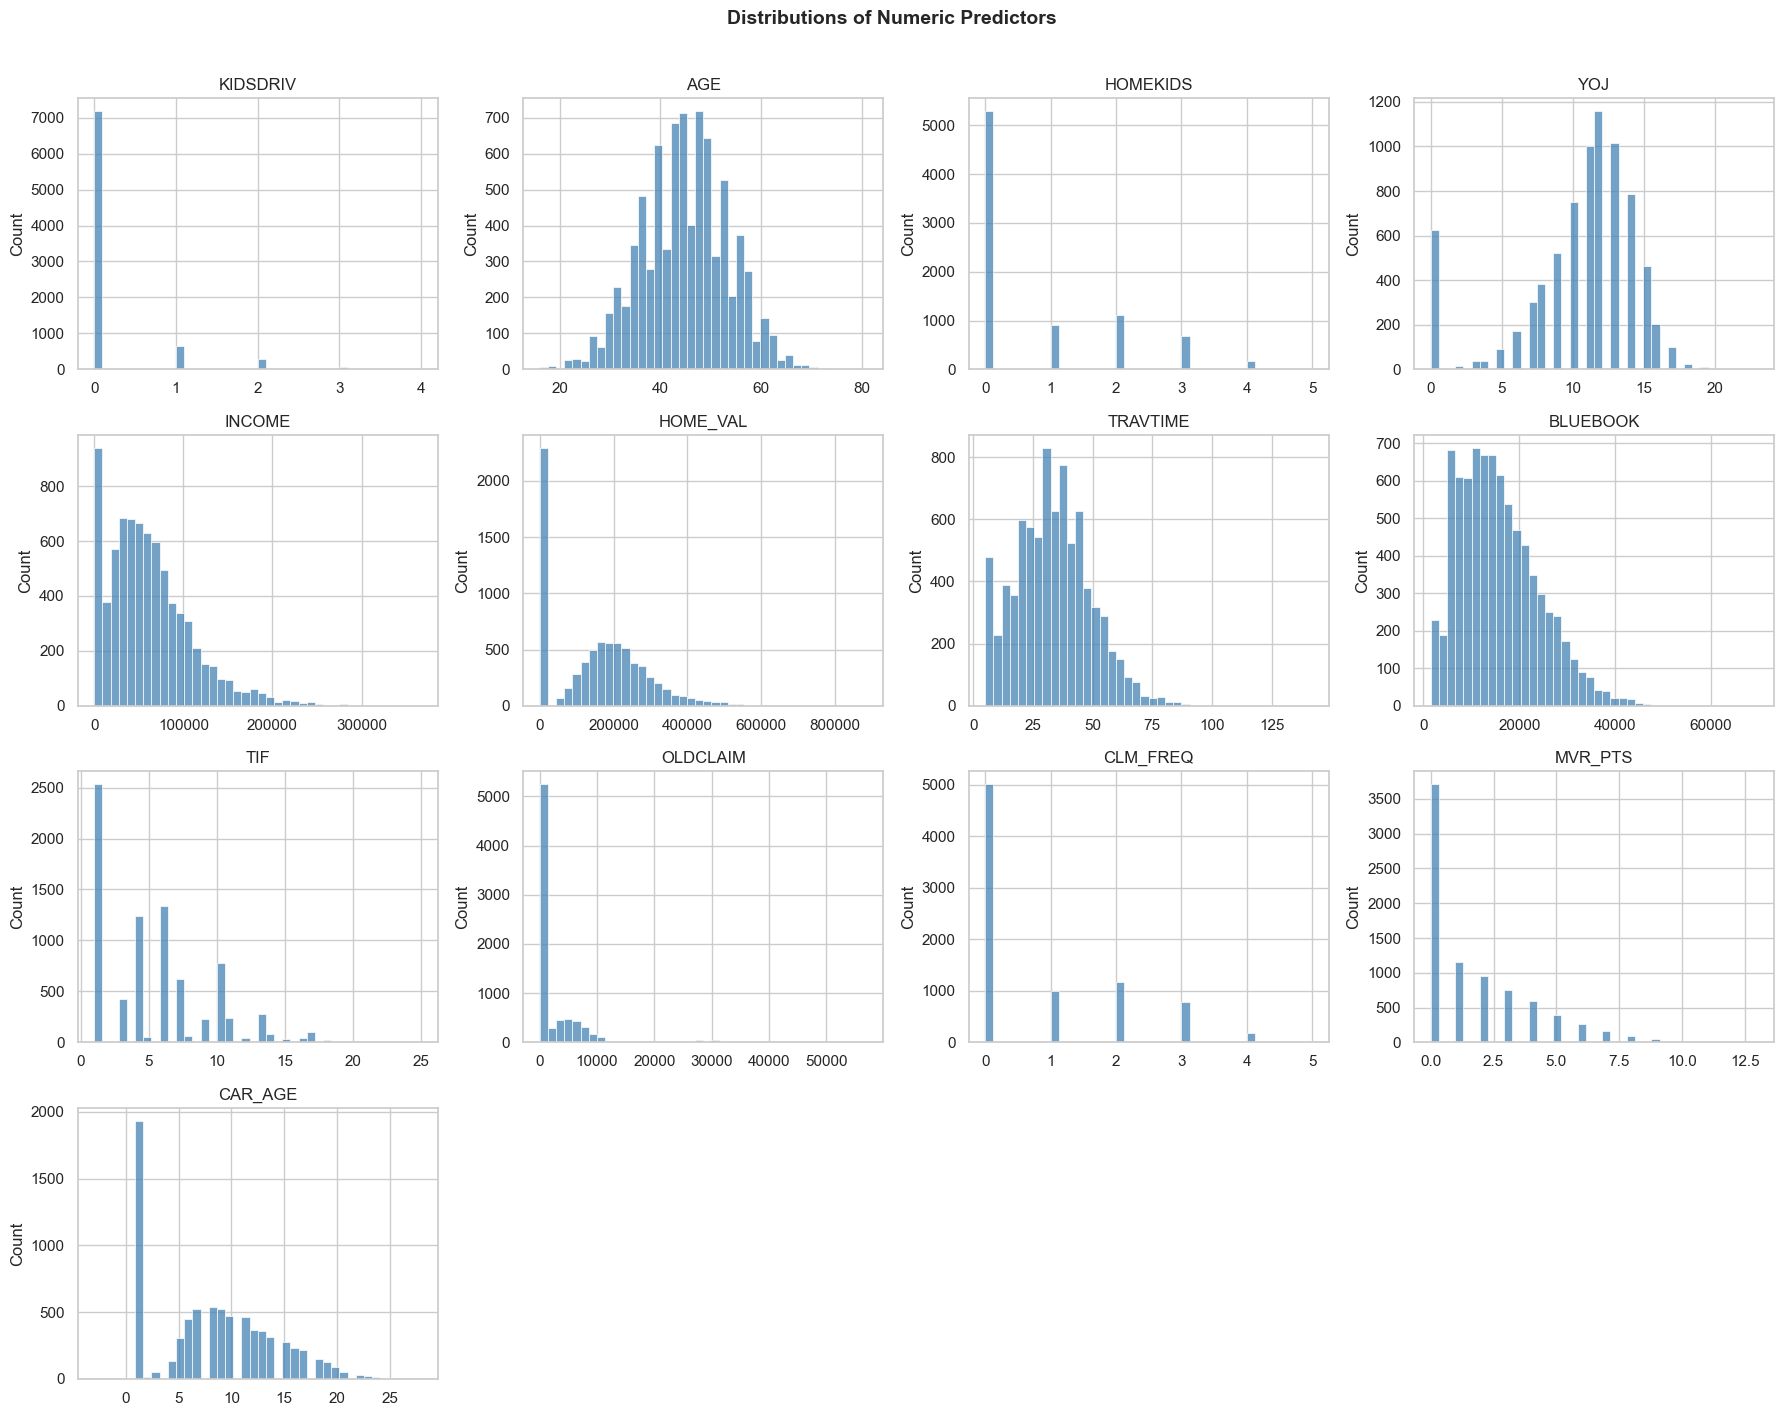

In [7]:
# Numeric predictors: histograms
fig, axes = plt.subplots(4, 4, figsize=(18, 14))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(train_df[col].dropna(), bins=40, ax=ax, color="steelblue")
    ax.set_title(col)
    ax.set_xlabel("")
for ax in axes.ravel()[len(num_cols):]:
    ax.set_visible(False)
plt.suptitle("Distributions of Numeric Predictors", y=1.01, fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

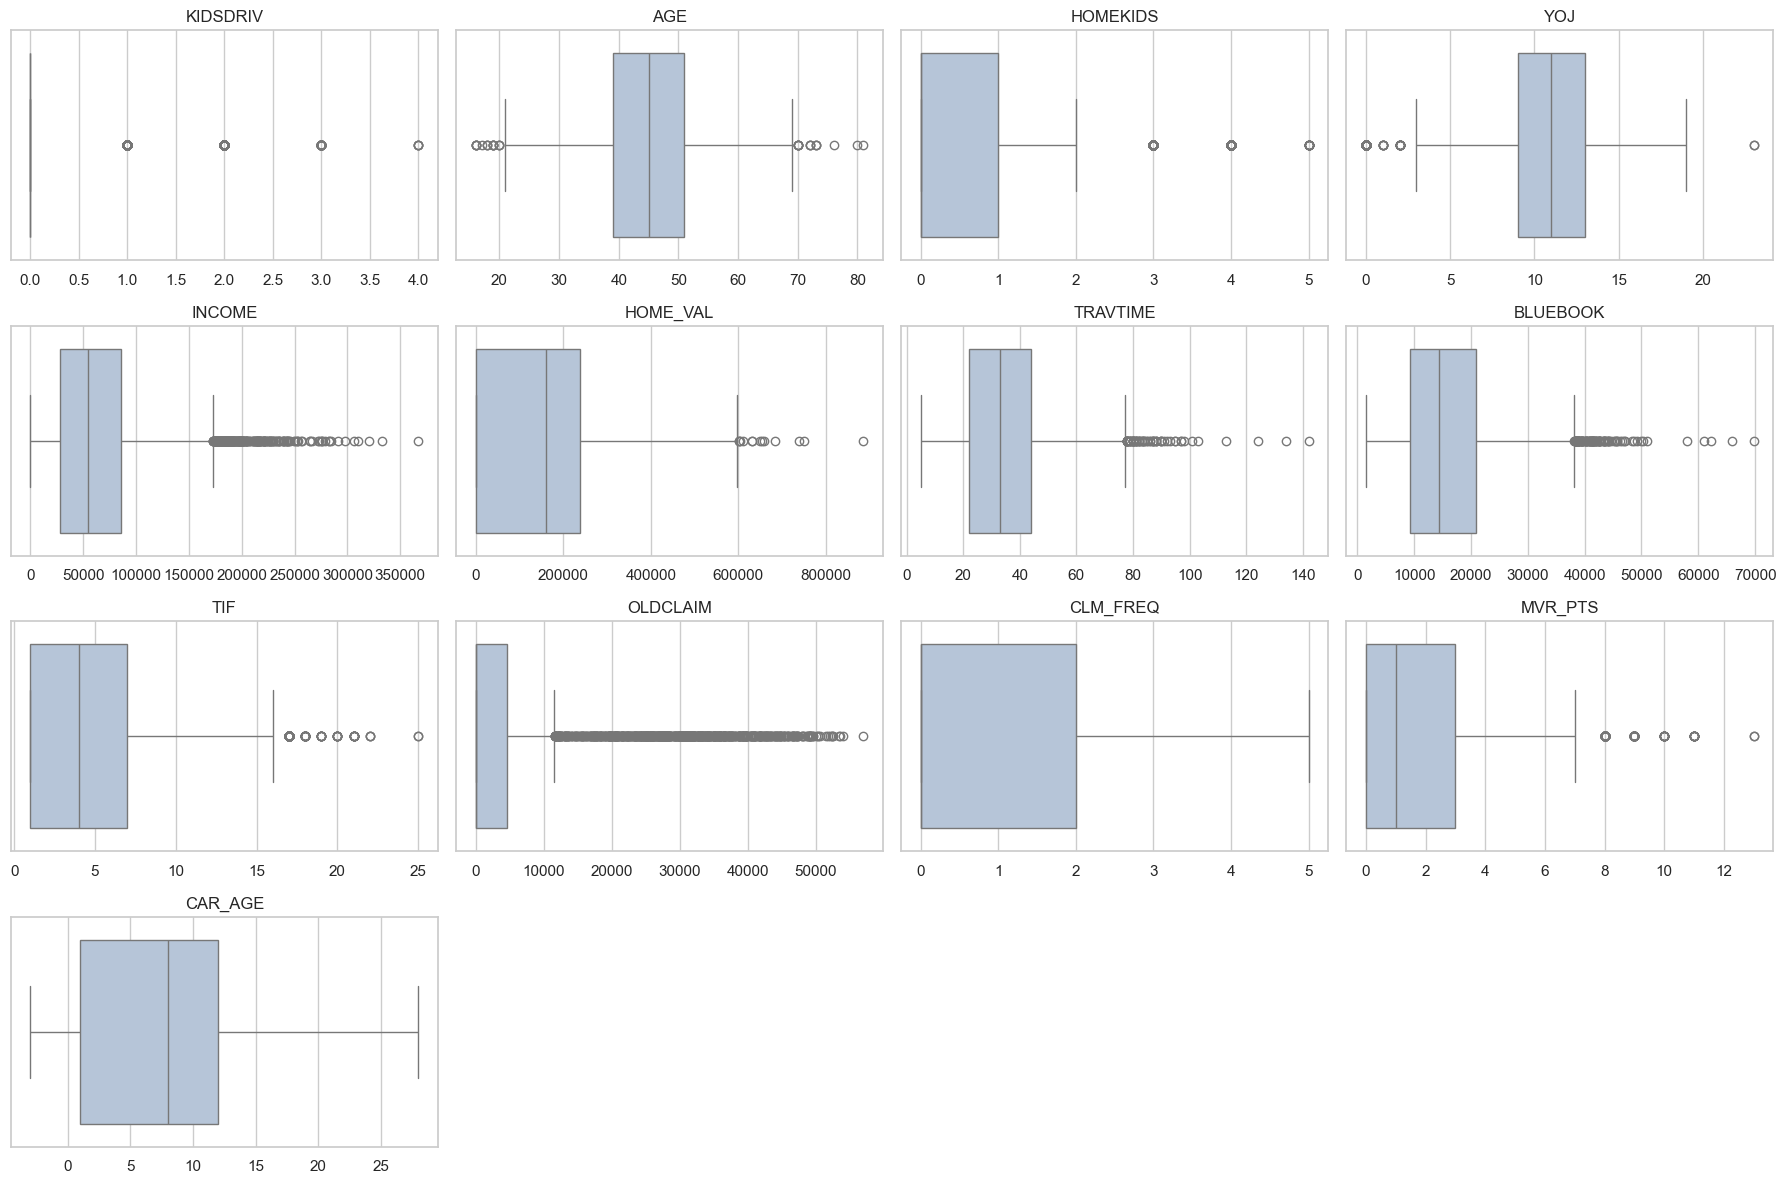

Negative CAR_AGE values: 1
Zero-valued HOME_VAL (likely renters): 2294
Zero-valued INCOME: 615
Age range: 16.0 - 81.0


In [8]:
# Outlier view: box plots of the numeric predictors
fig, axes = plt.subplots(4, 4, figsize=(18, 12))
for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(x=train_df[col], ax=ax, color="lightsteelblue")
    ax.set_title(col)
    ax.set_xlabel("")
for ax in axes.ravel()[len(num_cols):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

# Values that look suspicious
print("Negative CAR_AGE values:", (train_df["CAR_AGE"] < 0).sum())
print("Zero-valued HOME_VAL (likely renters):", (train_df["HOME_VAL"] == 0).sum())
print("Zero-valued INCOME:", (train_df["INCOME"] == 0).sum())
print("Age range:", train_df["AGE"].min(), "-", train_df["AGE"].max())

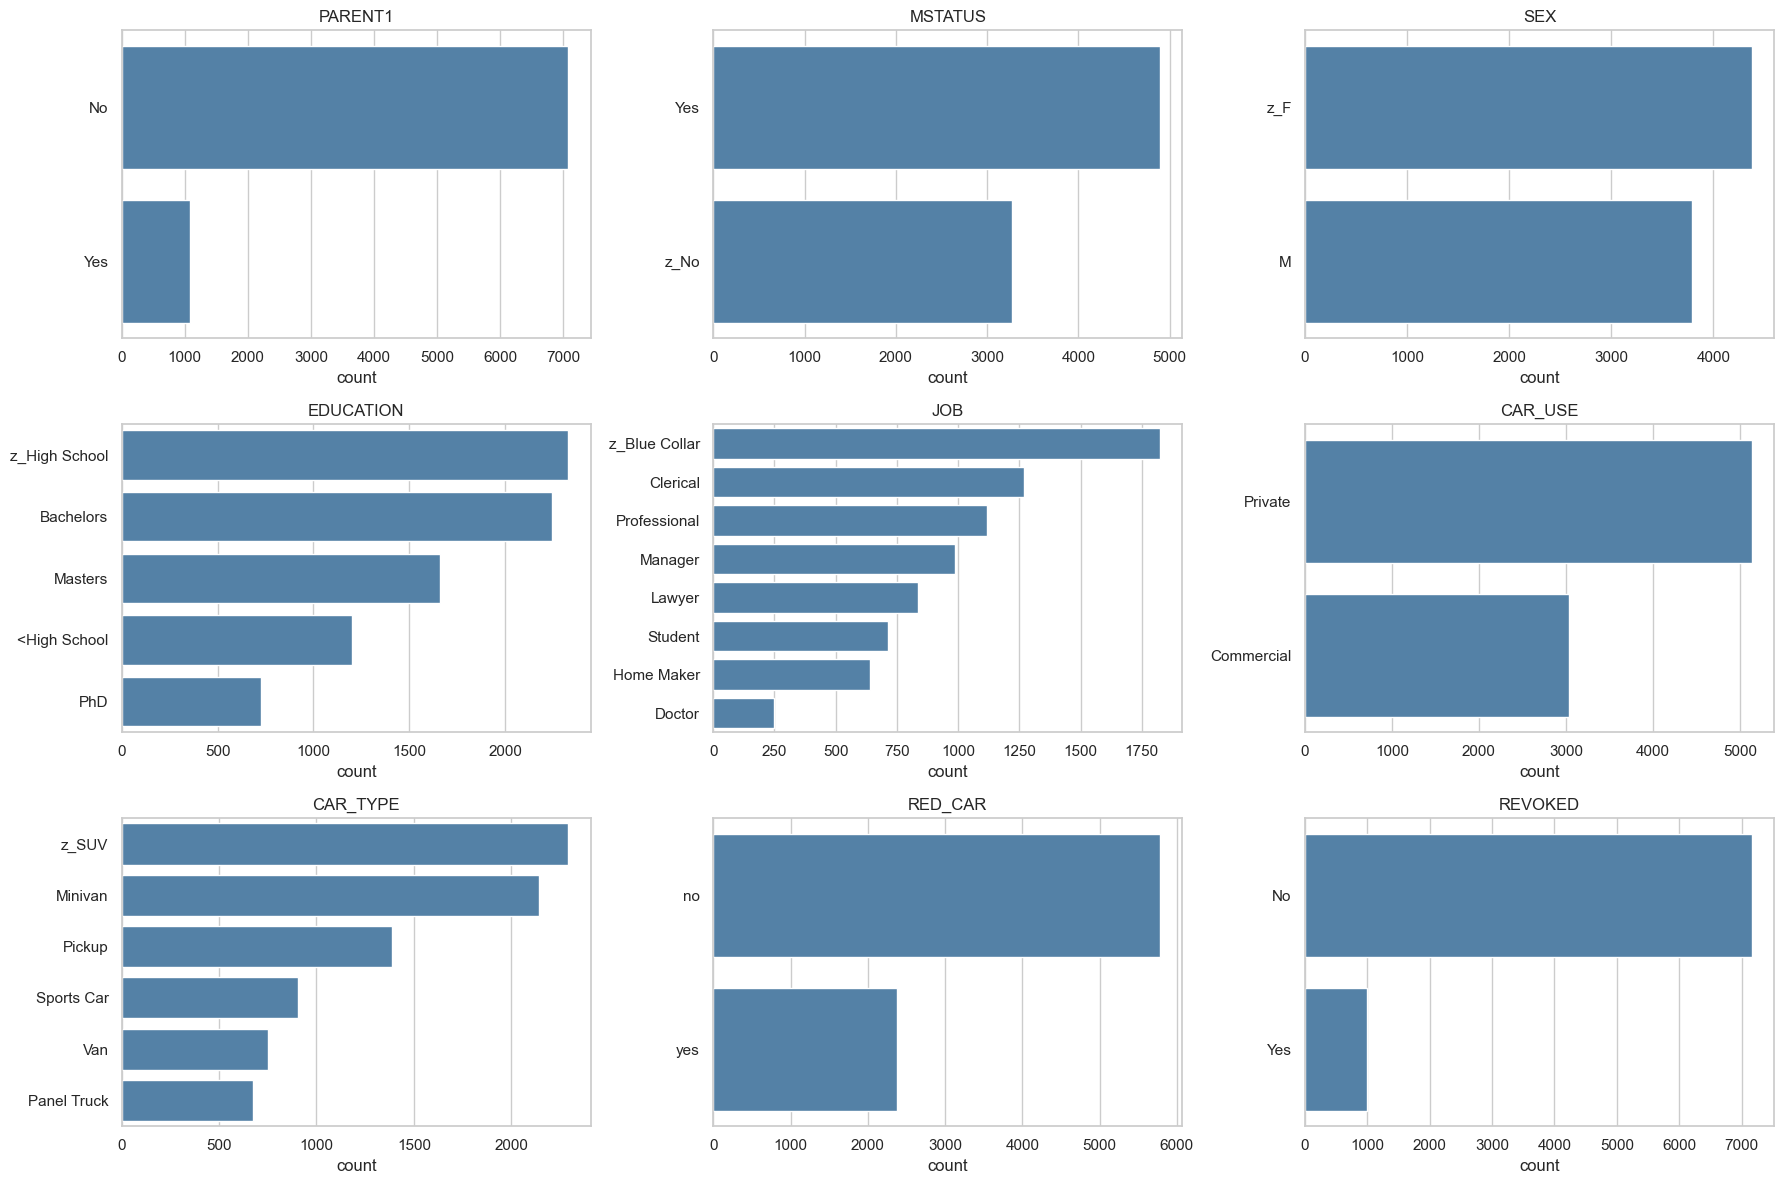

In [9]:
# Categorical predictors: counts per level
fig, axes = plt.subplots(3, 3, figsize=(18, 12))
for ax, col in zip(axes.ravel(), cat_cols):
    order = train_df[col].value_counts().index
    sns.countplot(y=col, data=train_df, order=order, ax=ax, color="steelblue")
    ax.set_title(col)
    ax.set_ylabel("")
for ax in axes.ravel()[len(cat_cols):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

`KIDSDRIV`, `OLDCLAIM`, `HOMEKIDS`, `CLM_FREQ` and `MVR_PTS` are zero-heavy and right-skewed, and `INCOME`, `HOME_VAL` and `BLUEBOOK` have long right tails. `HOME_VAL` is 0 for 2,294 customers (likely renters) and `INCOME` is 0 for 615, so zeros are meaningful values rather than missing data. `CAR_AGE` has a single impossible negative value (-3). The categorical variables carry inconsistent `z_` prefixes on some levels that should be cleaned.

## 1.4 Relationship with the Targets

We now look at which variables separate crashed from non-crashed customers, and at the crash rate within each categorical level, to compare against the theoretical effects given in the assignment.

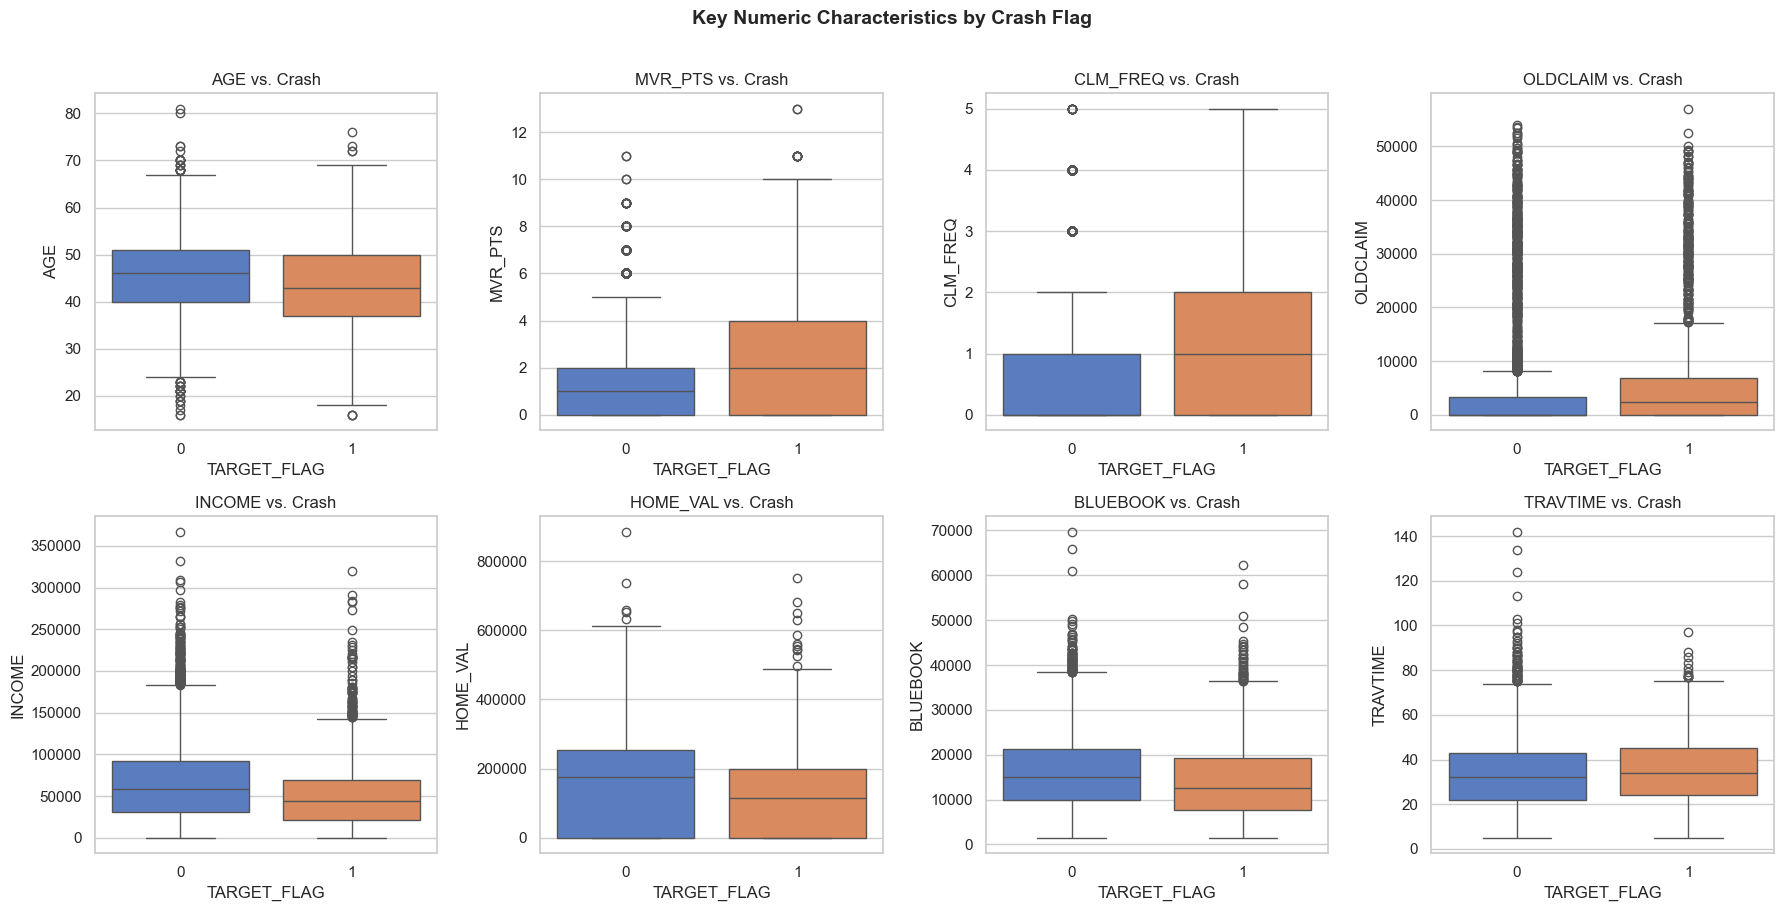

In [10]:
# Numeric predictors by crash flag
key_num = ["AGE", "MVR_PTS", "CLM_FREQ", "OLDCLAIM", "INCOME", "HOME_VAL", "BLUEBOOK", "TRAVTIME"]
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for ax, col in zip(axes.ravel(), key_num):
    sns.boxplot(x="TARGET_FLAG", y=col, data=train_df, hue="TARGET_FLAG", palette="muted", legend=False, ax=ax)
    ax.set_title(f"{col} vs. Crash")
plt.suptitle("Key Numeric Characteristics by Crash Flag", y=1.01, fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

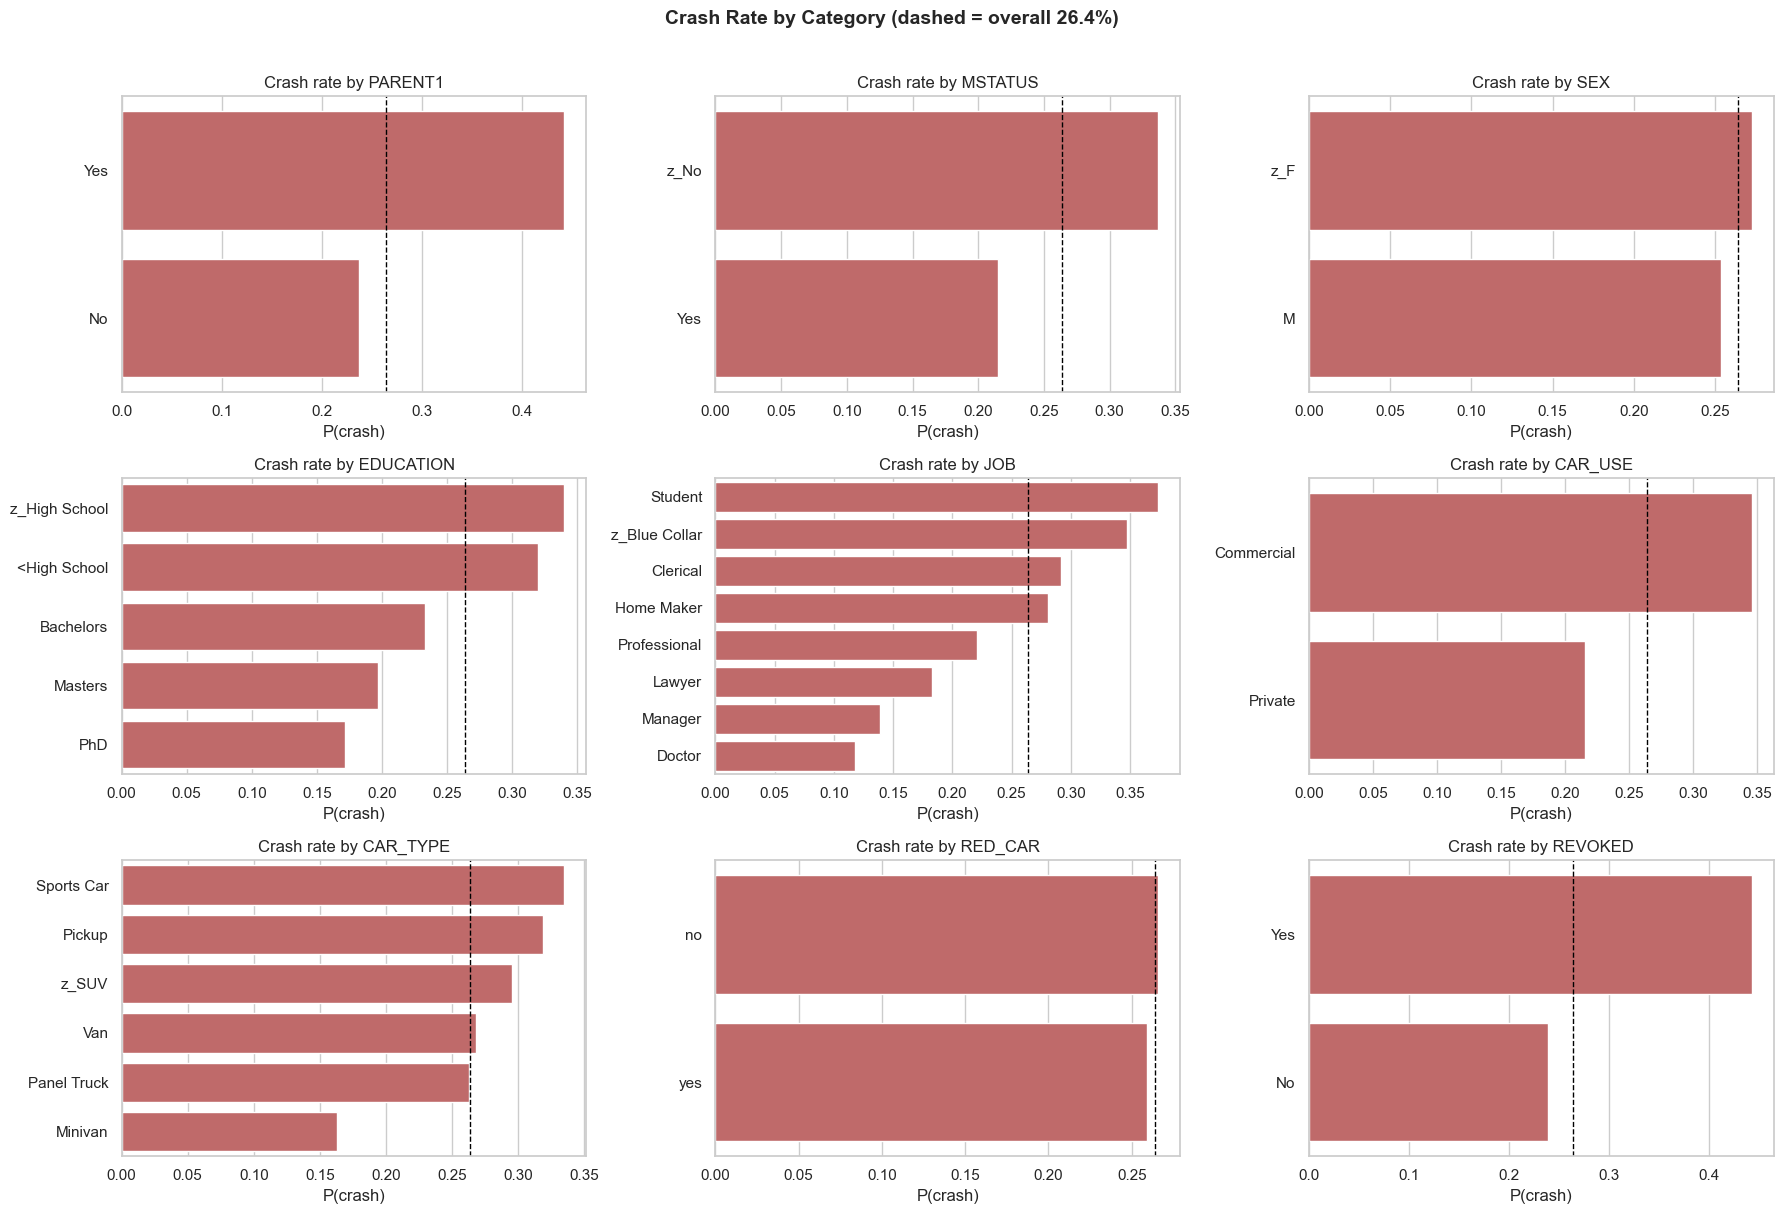

In [11]:
# Crash rate by categorical level
fig, axes = plt.subplots(3, 3, figsize=(18, 12))
overall = train_df["TARGET_FLAG"].mean()
for ax, col in zip(axes.ravel(), cat_cols):
    rate = train_df.groupby(col)["TARGET_FLAG"].mean().sort_values(ascending=False)
    sns.barplot(x=rate.values, y=rate.index, ax=ax, color="indianred")
    ax.axvline(overall, color="black", linestyle="--", linewidth=1)
    ax.set_title(f"Crash rate by {col}")
    ax.set_xlabel("P(crash)")
    ax.set_ylabel("")
for ax in axes.ravel()[len(cat_cols):]:
    ax.set_visible(False)
plt.suptitle(f"Crash Rate by Category (dashed = overall {overall:.1%})", y=1.01, fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

Crash risk differs sharply by group: urban customers crash at 31.4% versus 6.9% for rural, commercial use 34.6% versus private 21.6%, single parents 44.2%, and customers with a revoked license 44.3%. Students (37.4%) and blue-collar workers (34.7%) are riskiest, doctors (11.8%) and managers (13.9%) safest; minivans (16.3%) are far safer than sports cars (33.5%). Risk falls with education and for married customers. Gender (25.4% M vs 27.2% F) and red cars (25.9% vs 26.6%) show essentially no difference, so the urban legends are not supported.

## 1.5 Correlation & Redundancy (Multicollinearity)

We check how strongly each numeric variable correlates with the two targets and whether any predictors are redundant with one another, since highly correlated predictors destabilize regression coefficients.

,TARGET_FLAG,TARGET_AMT
MVR_PTS,0.219,0.138
CLM_FREQ,0.216,0.116
OLDCLAIM,0.138,0.071
HOMEKIDS,0.116,0.062
KIDSDRIV,0.104,0.055
TRAVTIME,0.048,0.028
YOJ,-0.071,-0.022
TIF,-0.082,-0.046
CAR_AGE,-0.101,-0.059
AGE,-0.103,-0.042


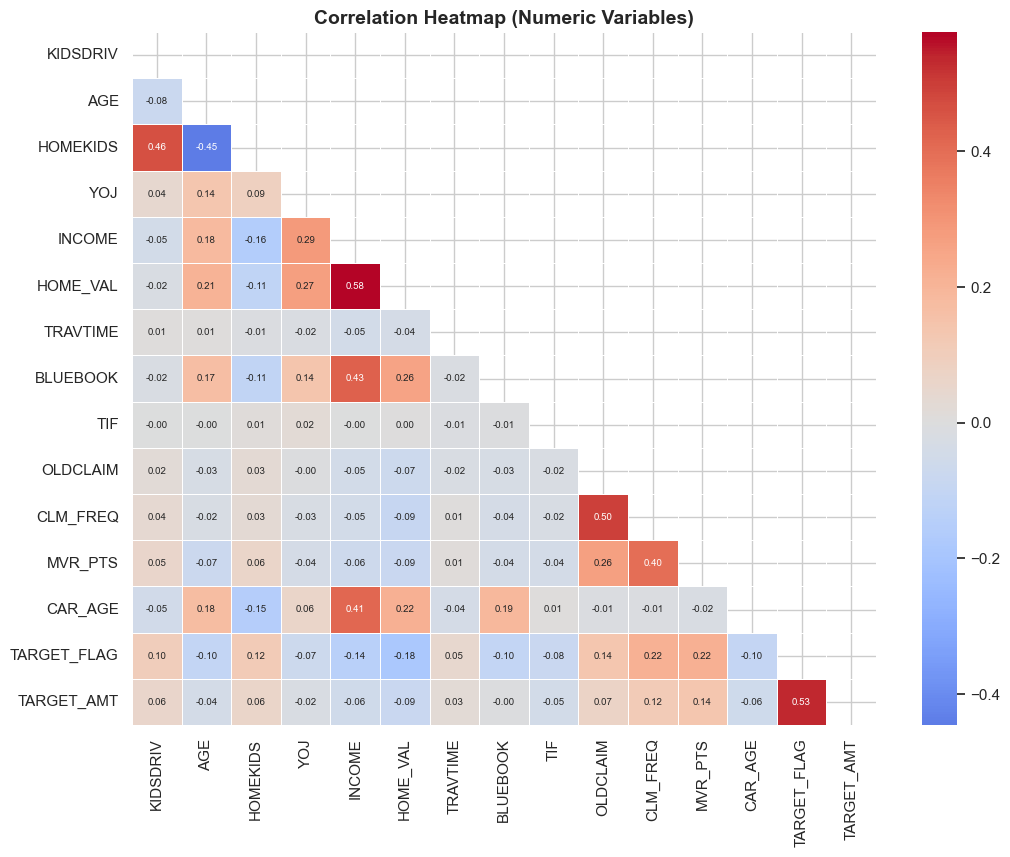

--- Strongest predictor pairs ---
INCOME    HOME_VAL    0.58
OLDCLAIM  CLM_FREQ    0.50
KIDSDRIV  HOMEKIDS    0.46
AGE       HOMEKIDS   -0.45
INCOME    BLUEBOOK    0.43
          CAR_AGE     0.41
CLM_FREQ  MVR_PTS     0.40
YOJ       INCOME      0.29


In [12]:
corr = train_df[num_cols + ["TARGET_FLAG", "TARGET_AMT"]].corr()

target_corr = corr[["TARGET_FLAG", "TARGET_AMT"]].drop(["TARGET_FLAG", "TARGET_AMT"]).sort_values("TARGET_FLAG", ascending=False).round(3)
display(target_corr)

plt.figure(figsize=(12, 9))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5, annot_kws={"size": 7})
plt.title("Correlation Heatmap (Numeric Variables)", fontsize=14, fontweight="bold")
plt.show()

# Strongest predictor-to-predictor pairs
pairs = corr.loc[num_cols, num_cols].where(np.triu(np.ones((len(num_cols),) * 2, dtype=bool), k=1)).stack()
print("--- Strongest predictor pairs ---")
print(pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(8).round(2).to_string())

The strongest linear correlations with a crash are driving-record variables: `MVR_PTS` (0.22) and `CLM_FREQ` (0.22), followed by `OLDCLAIM`, `HOMEKIDS` and `KIDSDRIV` (positive) and `HOME_VAL`, `INCOME` (negative). These signs agree with the theoretical effects in the assignment. Correlations with `TARGET_AMT` are weaker but have the same signs. No predictor pair exceeds 0.6 (`INCOME`/`HOME_VAL` at 0.58 is the highest), so severe multicollinearity is not expected, although `OLDCLAIM`/`CLM_FREQ` overlap by construction.

## 1.6 Missing Data Patterns

Six variables contain missing values. Before choosing an imputation strategy in Section 2, we check whether missingness is related to the outcome, which would justify creating missing-value flags.

In [13]:
miss_cols = missing.index.tolist()
rates = pd.DataFrame({
    col: train_df.groupby(train_df[col].isnull())["TARGET_FLAG"].mean() for col in miss_cols
}).T
rates.columns = ["crash rate (present)", "crash rate (missing)"]
rates["overall"] = overall
display((rates * 100).round(1))

,crash rate (present),crash rate (missing),overall
JOB,26.4,25.9,26.4
CAR_AGE,26.3,27.8,26.4
HOME_VAL,26.4,26.1,26.4
YOJ,26.3,27.1,26.4
INCOME,26.5,24.7,26.4
AGE,26.3,83.3,26.4


Six variables are missing between 0.1% and 6.5% of values (`JOB`, `CAR_AGE`, `HOME_VAL`, `YOJ`, `INCOME`, `AGE`), and the evaluation set has a similar pattern. Crash rates are nearly identical for present and missing values in every column except `AGE`, where the 6 missing customers crash far more often, but 6 records is too few to conclude anything. Missingness therefore looks essentially random, so simple median/mode imputation is reasonable; missing-value flags are optional and can be tested in Section 2.

# 2. Data Preparation 

Section 1 showed what needs fixing: inconsistent `z_` prefixes, one impossible `CAR_AGE`, six variables with missing values, zero-heavy and right-skewed numerics, and a skewed crash cost. This section will check each issue and adds a few variables that capture risk more directly than the raw columns.

To avoid data leakage and to guarantee the evaluation set gets identical treatment, every statistic used (medians, caps) is learned from the training set only and applied to both sets.

## 2.1 Clean Labels and Impossible Values

- Remove the `z_` prefix from categorical levels
- Negative `CAR_AGE` is impossible; we treat it as missing so it is imputed with the other missing car ages
- `AGE` of 16 to 81 is plausible, and the zeros in `INCOME` and `HOME_VAL` are real values (unemployed, renters), so they are kept

In [14]:
def clean_labels(df):
    df = df.copy()
    for col in df.select_dtypes(include="object").columns:
        df[col] = df[col].str.replace("z_", "", regex=False).str.strip()
    df["JOB"] = df["JOB"].replace("", np.nan)
    df.loc[df["CAR_AGE"] < 0, "CAR_AGE"] = np.nan
    return df

train_clean = clean_labels(train_df)
eval_clean = clean_labels(eval_df)

for col in ["EDUCATION", "JOB", "CAR_TYPE", "URBANICITY"]:
    print(f"{col}: {sorted(train_clean[col].dropna().unique())}")
print("Negative CAR_AGE values:", (train_clean["CAR_AGE"] < 0).sum())


EDUCATION: ['<High School', 'Bachelors', 'High School', 'Masters', 'PhD']
JOB: ['Blue Collar', 'Clerical', 'Doctor', 'Home Maker', 'Lawyer', 'Manager', 'Professional', 'Student']
CAR_TYPE: ['Minivan', 'Panel Truck', 'Pickup', 'SUV', 'Sports Car', 'Van']
URBANICITY: ['Highly Rural/ Rural', 'Highly Urban/ Urban']
Negative CAR_AGE values: 0


### 2.2 Missing Values: Flags and Imputation

Section 1.6 showed that missing values are nearly unrelated to crash risk, so simple imputation is appropriate:

- **Numeric** (`AGE`, `YOJ`, `INCOME`, `HOME_VAL`, `CAR_AGE`)  We use the median instead of the mean because these columns are skewed.
- **`JOB`**: Use a separate "Unknown" level rather than the mode, so we do not claim a job the customer may not have
- **Missing flags** (`JOB_MISSING`, `INCOME_MISSING`, `HOME_VAL_MISSING`): a 0/1 column for the three variables with the most missing values, so the model can check whether being missing matters. If it doesn't, the model will just give it a coefficient near zero

In [15]:
fill_cols = ["AGE", "YOJ", "INCOME", "HOME_VAL", "CAR_AGE"]
medians = train_clean[fill_cols].median()      # learned from training data only
print(medians.round(1).to_string())

def fill_missing(df):
    df = df.copy()
    for col in ["JOB", "INCOME", "HOME_VAL"]:
        df[f"{col}_MISSING"] = df[col].isnull().astype(int)
    df[fill_cols] = df[fill_cols].fillna(medians)
    df["JOB"] = df["JOB"].fillna("Unknown")
    return df

train_imp = fill_missing(train_clean)
eval_imp = fill_missing(eval_clean)

print("\nMissing left (train):", train_imp.drop(columns=["TARGET_AMT"]).isnull().sum().sum())
print("Missing left (eval): ", eval_imp.drop(columns=["TARGET_FLAG", "TARGET_AMT"]).isnull().sum().sum())

AGE             45.0
YOJ             11.0
INCOME       54028.0
HOME_VAL    161160.0
CAR_AGE          8.0

Missing left (train): 0
Missing left (eval):  0


### 2.3 Outliers, Transformations and New Variables

- **Capping:** Limit `INCOME`, `HOME_VAL`, `BLUEBOOK`, `OLDCLAIM`, `TRAVTIME` to their 1st and 99th percentiles since a few extreme values can pull a regression line too much
- **Square root:** Square root `SQRT_INCOME`, `SQRT_HOME_VAL`, `SQRT_BLUEBOOK` to reduce right skew. We tried log first, but it over-corrected these columns because of the zeros 
- **Log:** `LOG_OLDCLAIM` since `OLDCLAIM` has the longest tail, it needs the stronger log transform
- **Zero flags:** The zero values in `HOME_OWNER`, `HAS_INCOME`, `HAS_OLDCLAIM` are real groups (renters, no income, no past claim), and renters crash more (36.9% vs 22.3% for owners) 
- **Young driver flag:** `YOUNG_DRIVER` = age under 25  is a strong single flag with 57% crash rate vs 26% 
- **Bucket:** We can group ages in `CAR_AGE_GROUP` by New (0-3), Mid (4-10), Old (11+) to reduce noise
- **Combined variable:** Creating a new variable by combining 2 different variables `RISK_SCORE` = `MVR_PTS` + `CLM_FREQ` 

,skew before,skew after
INCOME,1.03,-0.37
HOME_VAL,0.37,-0.53
BLUEBOOK,0.63,-0.02
OLDCLAIM,3.00,0.53


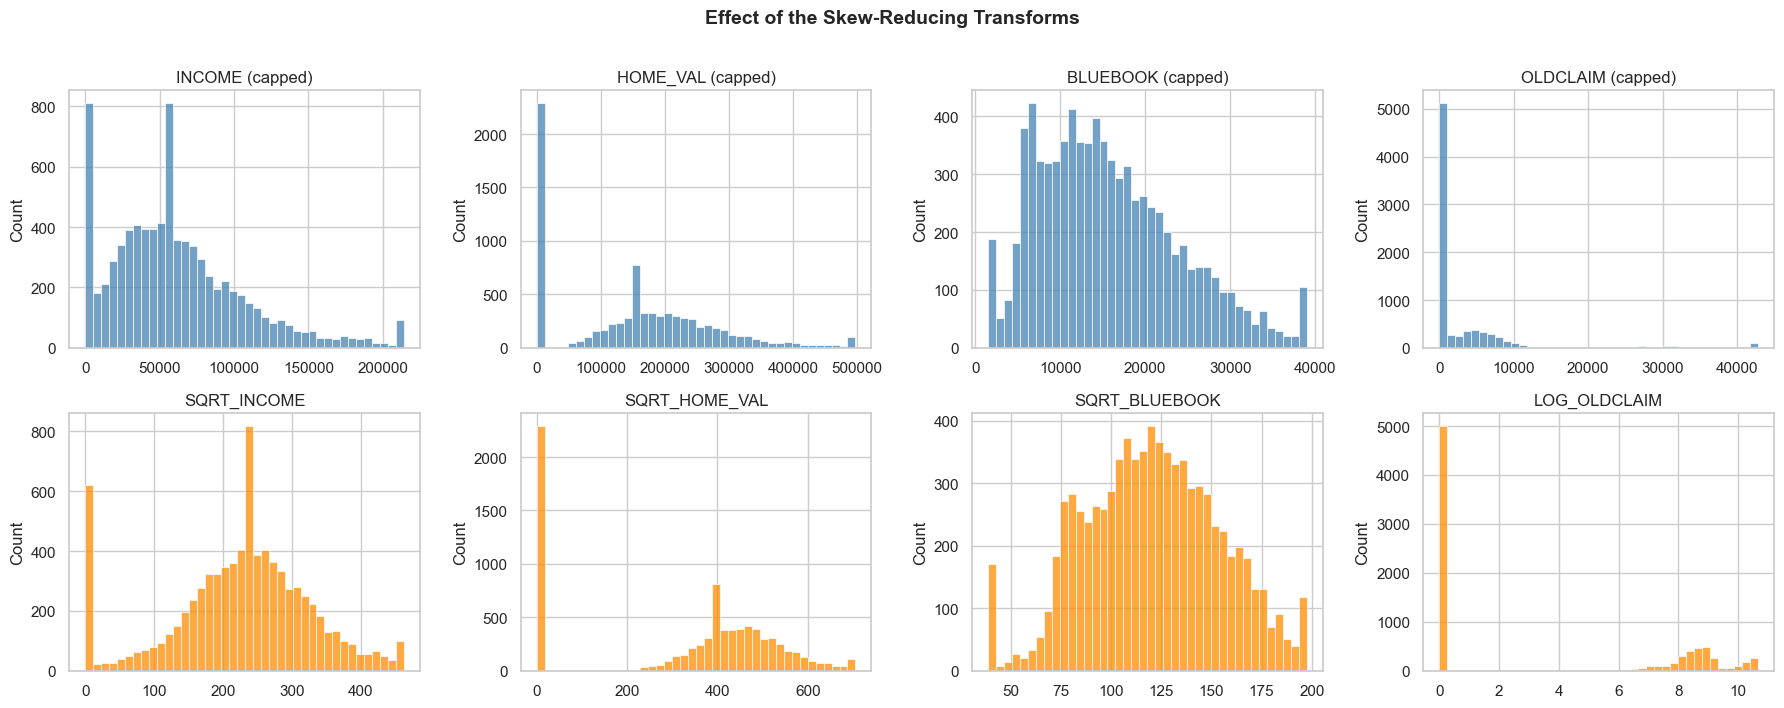

In [16]:
cap_cols = ["INCOME", "HOME_VAL", "BLUEBOOK", "OLDCLAIM", "TRAVTIME"]
caps = {c: (train_imp[c].quantile(0.01), train_imp[c].quantile(0.99)) for c in cap_cols} 

def transform(df):
    df = df.copy()

    # Flags (made before capping, using the original values)
    df["HOME_OWNER"] = (df["HOME_VAL"] > 0).astype(int)
    df["HAS_INCOME"] = (df["INCOME"] > 0).astype(int)
    df["HAS_OLDCLAIM"] = (df["OLDCLAIM"] > 0).astype(int)
    df["YOUNG_DRIVER"] = (df["AGE"] < 25).astype(int)

    # Cap extreme values
    for c, (low, high) in caps.items():
        df[c] = df[c].astype(float).clip(low, high)

    # Reduce skew
    for c in ["INCOME", "HOME_VAL", "BLUEBOOK"]:
        df[f"SQRT_{c}"] = np.sqrt(df[c])
    df["LOG_OLDCLAIM"] = np.log1p(df["OLDCLAIM"] )

    # Combined variable and bucket
    df["RISK_SCORE"] = df["MVR_PTS"] + df["CLM_FREQ"]
    df["CAR_AGE_GROUP"] = pd.cut(df["CAR_AGE"], [-np.inf, 3, 10, np.inf], labels=["New", "Mid", "Old"]).astype(str)
    return df

train_tf = transform(train_imp)
eval_tf = transform(eval_imp)


# Check improvement in skew
pairs = {"INCOME": "SQRT_INCOME", "HOME_VAL": "SQRT_HOME_VAL", "BLUEBOOK": "SQRT_BLUEBOOK", "OLDCLAIM": "LOG_OLDCLAIM"}
display(pd.DataFrame({
    "skew before": [train_tf[c].skew() for c in pairs],
    "skew after": [train_tf[v].skew() for v in pairs.values()],
}, index=pairs.keys()).round(2))


fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for i, (c, v) in enumerate(pairs.items()):
    sns.histplot(train_tf[c], bins=40, ax=axes[0, i], color="steelblue"); axes[0, i].set_title(f"{c} (capped)")
    sns.histplot(train_tf[v], bins=40, ax=axes[1, i], color="darkorange"); axes[1, i].set_title(v)
    axes[0, i].set_xlabel(""); axes[1, i].set_xlabel("")
plt.suptitle("Effect of the Skew-Reducing Transforms", y=1.01, fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

The tails are more balanced after the transforms, and `SQRT_BLUEBOOK` is almost a bell shape. The spikes at zero in `SQRT_INCOME`, `SQRT_HOME_VAL` and `LOG_OLDCLAIM` are left purposefully. They are real groups (no income, renters, no past claim), and no transform can move a zero. That is why we added the `HAS_INCOME`, `HOME_OWNER` and `HAS_OLDCLAIM` flags. The flag handles "zero or not" and the transformed column handles "how much."

### 2.4 Check the New Variables

Before modeling, we confirm if the engineered variables actually separate risk groups to justify keeping them.

,crash rate % (0),crash rate % (1)
HOME_OWNER,36.9,22.3
HAS_INCOME,40.7,25.2
HAS_OLDCLAIM,17.9,39.8
YOUNG_DRIVER,26.1,56.9


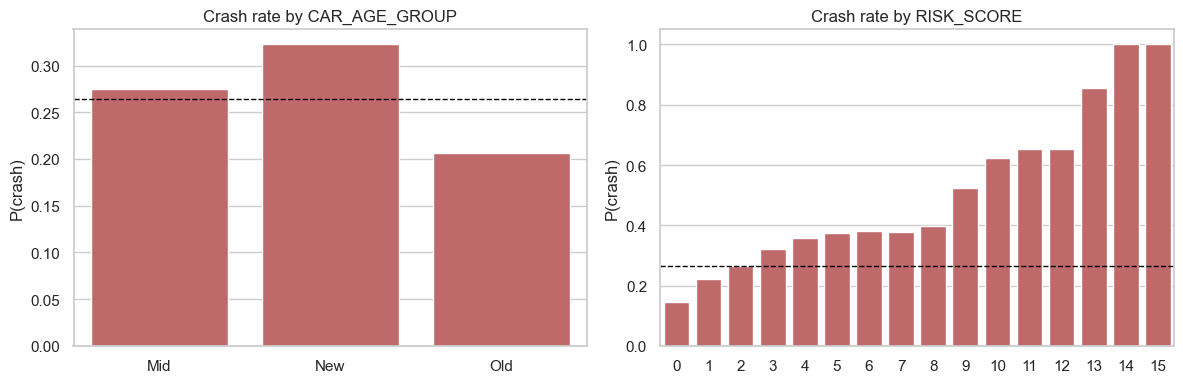

In [17]:
flags = ["HOME_OWNER", "HAS_INCOME", "HAS_OLDCLAIM", "YOUNG_DRIVER"]
check = pd.DataFrame({v: train_tf.groupby(v)["TARGET_FLAG"].mean() * 100 for v in flags}).T
check.columns = ["crash rate % (0)", "crash rate % (1)"]
display(check.round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, v in zip(axes, ["CAR_AGE_GROUP", "RISK_SCORE"]):
    rate = train_tf.groupby(v)["TARGET_FLAG"].mean()
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax, color="indianred" )
    ax.axhline(overall, color="black", linestyle="--", linewidth=1)
    ax.set_title(f"Crash rate by {v}"); ax.set_ylabel("P(crash)"); ax.set_xlabel("")

plt.tight_layout()
plt.show()

All four flags show a clear gap in crash rate, the crash rate climbs with `RISK_SCORE` (about 15% at 0 to over 60% at 10+), and car age groups differ (New 32%, Mid 28%, Old 21%), so the new variables appear to be useful. The dashed line represents overall crash rate.

### 2.5 Encode Categorical Variables

Regression needs numeric inputs:

- Two-level variables become 0/1 indicators. We name them after the level we expect to be riskier (like `REVOKED`, `URBAN`), so the coefficient is easy to read
- Multi-level variables (`EDUCATION`, `JOB`, `CAR_TYPE`, `CAR_AGE_GROUP`) become one 0/1 column per level using `get_dummies`. One level is dropped as the reference group, and the other levels are compared against it. Dropping one avoids a redundant column that would break the regression
- The evaluation set is lined up to the training columns so both have the same columns

In [ ]:
def encode(df):
    out = df.copy()
    out["PARENT1"] = (out["PARENT1"] =="Yes").astype(int)
    out["MSTATUS"] =(out["MSTATUS"] == "Yes").astype(int)       
    out["MALE"] = (out["SEX"] == "M").astype(int)
    out["COMMERCIAL_USE"]= (out["CAR_USE"] == "Commercial" ).astype(int)
    out["RED_CAR"] = (out["RED_CAR"] == "yes").astype(int)
    out["REVOKED"] = (out["REVOKED"]=="Yes").astype(int)
    out["URBAN"]=out["URBANICITY"].str.startswith("Highly Urban").astype(int)
    out = out.drop(columns=["SEX", "CAR_USE", "URBANICITY"])
    return pd.get_dummies(out, columns=["EDUCATION", "JOB", "CAR_TYPE", "CAR_AGE_GROUP"], drop_first=True, dtype=int)

train_enc = encode(train_tf)
eval_enc = encode(eval_tf).reindex(columns=train_enc.columns, fill_value=0) 

# Reference groups (the level that was dropped for each category)
for col in ["EDUCATION", "JOB","CAR_TYPE", "CAR_AGE_GROUP"]:
    print(f"Reference group for {col}: {sorted(train_tf[col].unique())[0]}" )

print(f"\nEncoded training set:{train_enc.shape}")

print(f"Encoded evaluation set:{eval_enc.shape}")

Reference group for EDUCATION: <High School
Reference group for JOB: Blue Collar
Reference group for CAR_TYPE: Minivan
Reference group for CAR_AGE_GROUP: Mid

Encoded training set:   (8161, 54)
Encoded evaluation set: (2141, 54)


### 2.6 Final Modeling Datasets

For the **crash flag** models we use all customers. For the **crash cost** models we use only customers who crashed, because `TARGET_AMT` is 0 for everyone else and including them would make the model mostly predict "did they crash" instead of "how much did it cost." Crash costs are also very skewed (5.64), so we make a log version, `y_train_log_amt`, which brings the skew to about 0.

In [ ]:
id_cols = ["INDEX", "TARGET_FLAG", "TARGET_AMT"]
feature_cols = [c for c in train_enc.columns if c not in id_cols]

X_train = train_enc[feature_cols ]
X_eval = eval_enc[feature_cols]
y_flag = train_enc["TARGET_FLAG"]
y_amt = train_enc["TARGET_AMT"]

# Crash cost data for crashed customers only
crash_mask = y_flag == 1
X_train_amt = X_train[crash_mask]
y_train_amt= y_amt[crash_mask]
y_train_log_amt= np.log1p(y_train_amt)

# Safety checks
assert list(X_train.columns)== list(X_eval.columns)
assert X_train.isnull().sum().sum() == 0 and X_eval.isnull().sum().sum() == 0

print(f"Predictors: {len(feature_cols)}")
print(f"Crash flag training: {X_train.shape[0]:,} rows ({y_flag.mean():.1%} crashes)")
print(f"Crash cost training:{X_train_amt.shape[0]:,} rows (crashed only) ")
print(f"Evaluation set:{X_eval.shape[0]:,} rows")
print(f"TARGET_AMT skew: {y_train_amt.skew():.2f} ")
print(f"TARGET_AMT skew after log: {y_train_log_amt.skew():.2f}" )


# Saved file for modeling
train_enc.to_csv("train_clean.csv", index=False)
eval_enc.to_csv("eval_clean.csv", index=False)

Predictors: 51
Crash flag training: 8,161 rows (26.4% crashes)
Crash cost training:2,153 rows (crashed only) 
Evaluation set:2,141 rows
TARGET_AMT skew: 5.64 
TARGET_AMT skew after log: -0.01


### 2.7 Summary

In this section we cleaned the insurance data and got it ready for modeling. We removed the `z_` prefixes from the category labels and treated the one impossible car age (-3) as missing. Missing numbers were filled with the training-set median, missing job titles were labeled "Unknown", and we added missing-value flags for `JOB`, `INCOME` and `HOME_VAL`. We capped extreme values at the 1st and 99th percentiles, then used square root transforms for `INCOME`, `HOME_VAL` and `BLUEBOOK` and a log transform for `OLDCLAIM` to reduce skew. The zero spikes that remain in those columns are real groups (no income, renters, no past claims), so we added `HOME_OWNER`, `HAS_INCOME` and `HAS_OLDCLAIM` flags to represent them. We also created `YOUNG_DRIVER` (under 25, which had a 57% crash rate versus 26%), `CAR_AGE_GROUP` buckets, and `RISK_SCORE` (`MVR_PTS` plus `CLM_FREQ`). Finally, we converted all categories to 0/1 columns, giving 51 predictors with no missing values. For the cost models, we use only customers who crashed and a log version of `TARGET_AMT`, since costs are very skewed.